# Exercice 12

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

titanic = pd.read_csv("../data/titanic_propre.csv")
taxis = sns.load_dataset("taxis")
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

## 1. L'âge des passagers

Une variable quantitative donc un histogramme. Je prends les données de base pour ne pas avoir les âges imputés.

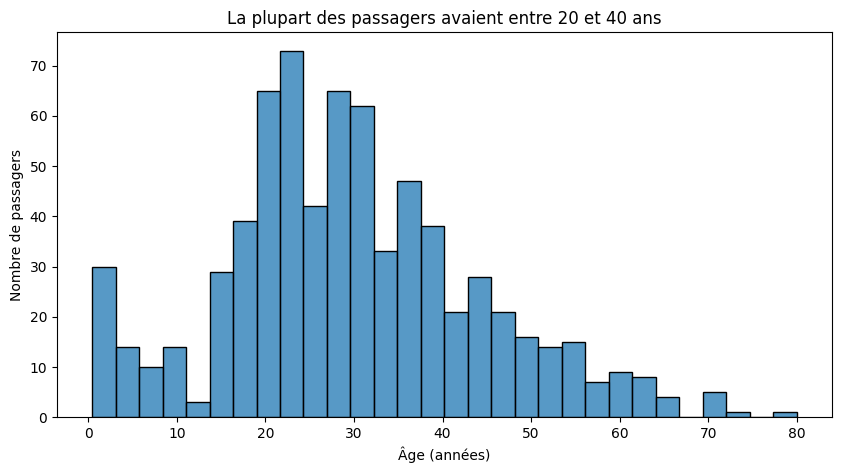

In [2]:
titanic_brut = sns.load_dataset("titanic")

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=titanic_brut, x="age", bins=30, ax=ax)
ax.set_title("La plupart des passagers avaient entre 20 et 40 ans")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre de passagers")
fig.savefig("figures/01_ages.png", dpi=150, bbox_inches="tight")
plt.show()

Conclusion : la plupart des passagers étaient de jeunes adultes.

## 2. Survie selon la classe et le sexe

Une mesure par catégorie donc des barres, avec le sexe en couleur.

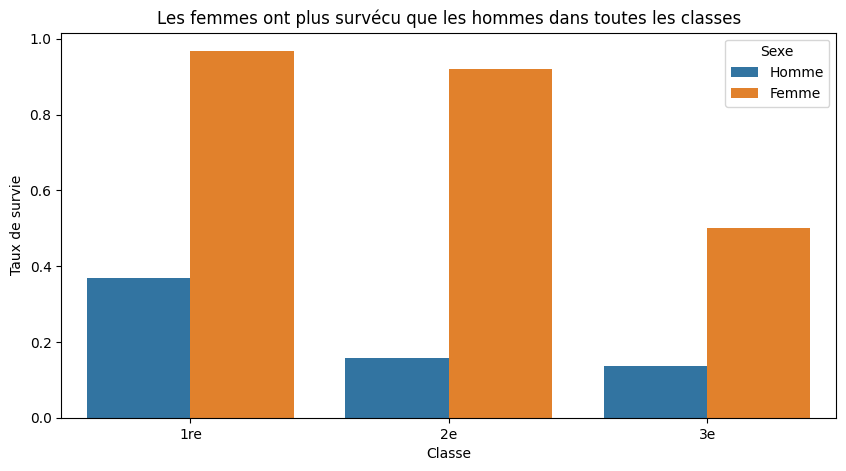

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=titanic, x="class", y="survived", hue="sex", order=["First", "Second", "Third"], errorbar=None, ax=ax)
ax.set_xticks([0, 1, 2], ["1re", "2e", "3e"])
ax.set_title("Les femmes ont plus survécu que les hommes dans toutes les classes")
ax.set_xlabel("Classe")
ax.set_ylabel("Taux de survie")
ax.legend(title="Sexe", labels=["Homme", "Femme"])
fig.savefig("figures/02_survie.png", dpi=150, bbox_inches="tight")
plt.show()

Conclusion : les femmes de 1re classe ont presque toutes survécu, les hommes de 3e très peu.

## 3. Prix du billet selon la classe

Une mesure par catégorie donc des boîtes.

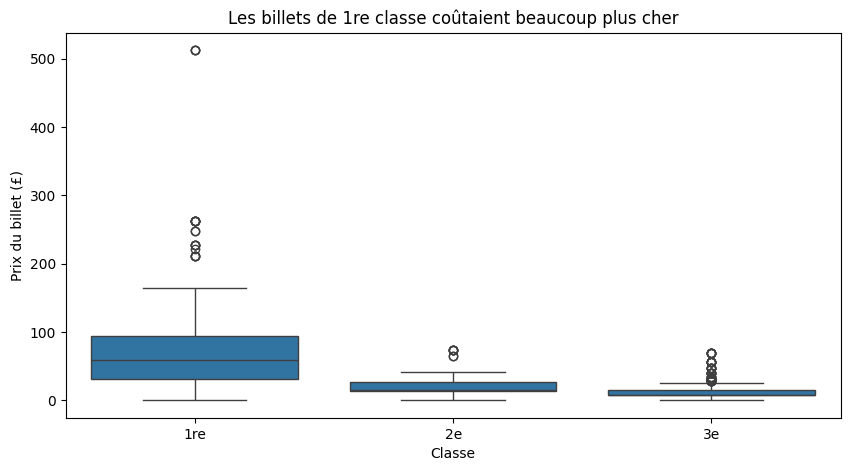

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=titanic, x="class", y="fare", order=["First", "Second", "Third"], ax=ax)
ax.set_xticks([0, 1, 2], ["1re", "2e", "3e"])
ax.set_title("Les billets de 1re classe coûtaient beaucoup plus cher")
ax.set_xlabel("Classe")
ax.set_ylabel("Prix du billet (£)")
fig.savefig("figures/03_prix.png", dpi=150, bbox_inches="tight")
plt.show()

Conclusion : le prix médian est de 60 £ en 1re classe contre 8 £ en 3e.

## 4. Taxis : chiffre d'affaires par jour

Une évolution dans le temps donc une courbe.

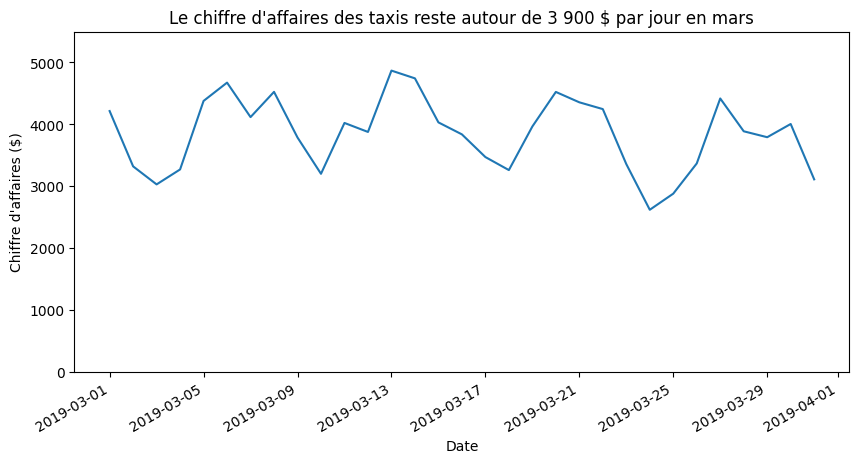

In [5]:
taxis_mars = taxis[taxis["pickup"] >= "2019-03-01"]
ca_par_jour = taxis_mars.set_index("pickup").resample("D")["total"].sum()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x=ca_par_jour.index, y=ca_par_jour.values, ax=ax)
ax.set_title("Le chiffre d'affaires des taxis reste autour de 3 900 $ par jour en mars")
ax.set_xlabel("Date")
ax.set_ylabel("Chiffre d'affaires ($)")
ax.set_ylim(0, 5500)
fig.autofmt_xdate()
fig.savefig("figures/04_ca_taxis.png", dpi=150, bbox_inches="tight")
plt.show()

Je garde seulement mars car le 28 février n'a qu'une course.

Conclusion : le chiffre d'affaires change selon les jours (entre 2 600 et 4 900 $) mais reste stable sur le mois.

## 5. Taxis : distance et prix

Deux variables quantitatives donc un nuage de points.

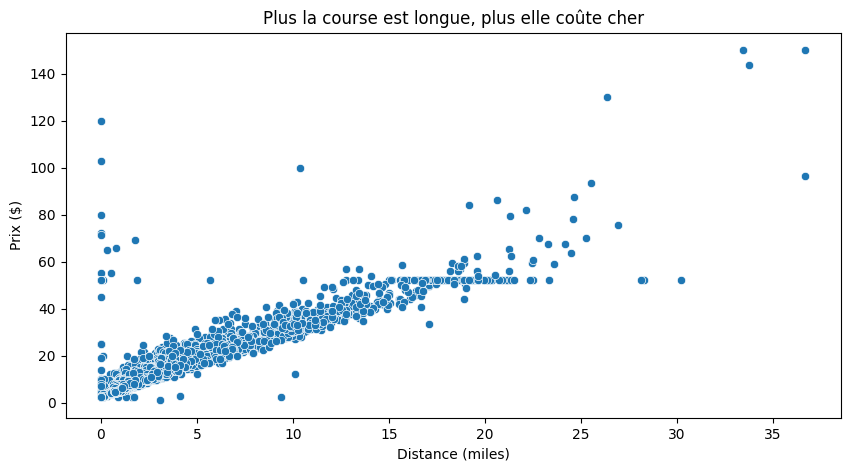

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=taxis, x="distance", y="fare", ax=ax)
ax.set_title("Plus la course est longue, plus elle coûte cher")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Prix ($)")
fig.savefig("figures/05_distance_prix.png", dpi=150, bbox_inches="tight")
plt.show()

Conclusion : le prix augmente presque en ligne droite avec la distance.